# v3: relabel with round 2's best model, then a new model from scratch

Same as v2 (`train_v2.ipynb`) except where the training labels come from:

1. **Relabel**: `../models/captcha_cnn_v2_ft.pt` (gold 98.5%) reads every captcha → `../data/labels_v3.csv`.
   v2 trusted only reads where v1 and Apple Vision agreed; that kept ~1,700 shared mistakes (g/9, i/j, Y/y) and threw
   away hard cases Vision misreads. Now every read with confidence ≥ `MIN_CONF` is a training label, Vision or not.
2. **Train** a new model **from scratch** on those labels + your reviews (so v1's habits don't carry over). **Test** on gold.
3. **Fine-tune** on all your reviews (`../data/reviews.json`, shared with v2), then **review** 50 at a time and repeat.

Gold (`../data/gold.csv`, 200 checked) is unchanged and never trained on, so scores compare directly with v2 (98.5%).

## 1. Setup and paths

In [1]:
import csv, json, math, os, random, sys, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

sys.path.insert(0, "../scripts")
import prep   # ink(): red-letter mask, Vision helpers; shared with scripts/label_vision.py

# images: ../data/captchas.zip (100,000 captchas), read with prep.open_captcha(id); no loose PNGs
GOLD_CSV = "../data/gold.csv"                # 200 test captchas, never trained on or reviewed (audit_gold.py)
REVIEWS = "../data/reviews.json"             # your typed answers (review.py adds to it)
VISION_LABELS = "../data/labels_vision.csv"  # Apple Vision's read of every captcha (scripts/label_vision.py)
TEACHER = "../models/captcha_cnn_v2_ft.pt"   # round 2's best (gold 98.5%): relabels every captcha
LABELS_CSV = "../data/labels_v3.csv"         # written by the relabel cell
CACHE = "../cache/ink_images.npz"            # cleaned images, so re-runs skip reading 100k PNGs
MODEL_PATH = "../models/captcha_cnn_v3.pt"   # the new baseline
FT_PATH = "../models/captcha_cnn_v3_ft.pt"   # the new baseline fine-tuned on your reviews
os.makedirs("../models", exist_ok=True)
os.makedirs("../cache", exist_ok=True)

SEED = 0
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

_teacher = torch.load(TEACHER, map_location="cpu")
ALPHABET, LENGTH = _teacher["alphabet"], _teacher["length"]   # same classes as v1, v2 and the extension
assert (ALPHABET, LENGTH) == (prep.ALPHABET, prep.LENGTH)
CHAR_TO_IDX = {c: i for i, c in enumerate(ALPHABET)}
print("device:", DEVICE, "| alphabet:", ALPHABET)

device: mps | alphabet: 2345689ABDEFGHJLMNQRTYabdefghijmnqrty


/Users/varunmatta/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load all images (red letters only, cached after the first run, ~1–2 min), Vision reads and gold

In [2]:
ALL_IDS = np.array(prep.captcha_ids())

cached = np.load(CACHE) if os.path.exists(CACHE) else None
if cached is not None and np.array_equal(cached["ids"], ALL_IDS):
    imgs = cached["imgs"]
else:
    t = time.time()
    with ThreadPoolExecutor(8) as ex:
        imgs = np.stack(list(ex.map(lambda i: prep.ink(prep.open_captcha(i)), ALL_IDS)))
    np.savez(CACHE, ids=ALL_IDS, imgs=imgs)
    print(f"read {len(imgs)} images in {time.time() - t:.0f}s")
H, W = imgs.shape[1:]
X = torch.from_numpy(imgs).to(DEVICE)   # uint8, all images on the GPU (~0.7 GB)
row_of = {i: k for k, i in enumerate(ALL_IDS)}

VISION = {}   # id -> Vision's read, "" where it gave no valid 5-character answer
if os.path.exists(VISION_LABELS):
    with open(VISION_LABELS) as f:
        VISION = {r["id"]: r["vision"] for r in csv.DictReader(f)}
GOLD = {}     # id -> {label, model, vision, checked}; filled by audit_gold.py
if os.path.exists(GOLD_CSV):
    with open(GOLD_CSV) as f:
        GOLD = {r["id"]: r for r in csv.DictReader(f)}
print("images:", imgs.shape, f"| Vision reads: {len(VISION)}/{len(ALL_IDS)}",
      f"| gold: {len(GOLD)} ({sum(bool(g['checked']) for g in GOLD.values())} checked)")

images: (100000, 45, 150) | Vision reads: 100000/100000 | gold: 200 (200 checked)


## 3. Model definition and helpers (same network as v1)

In [3]:
class CaptchaCNN(nn.Module):
    def __init__(self, n_classes, length=LENGTH, widths=(32, 64, 128, 192), dropout=0.3):
        super().__init__()
        layers, c_in = [], 1
        for c in widths:   # each block halves H and W: 45x150 -> 2x9
            layers += [
                nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            ]
            c_in = c
        self.features = nn.Sequential(*layers)
        n_cols = W // 2 ** len(widths)   # 9 columns left, kept apart so heads know left from right
        self.shared = nn.Sequential(nn.Flatten(), nn.Dropout(dropout),
                                    nn.Linear(c_in * n_cols, 512), nn.ReLU(inplace=True), nn.Dropout(dropout))
        self.heads = nn.ModuleList(nn.Linear(512, n_classes) for _ in range(length))

    def forward(self, x):
        z = self.features(x).mean(dim=2)   # average over height -> (B, C, columns)
        z = self.shared(z)
        return torch.stack([head(z) for head in self.heads], dim=1)   # (B, LENGTH, n_classes)

def to_input(x):
    """uint8 (B, H, W) -> float (B, 1, H, W) with ink = 1, paper = 0."""
    return (1 - x.float() / 255).unsqueeze(1)

def load_model(path):
    ckpt = torch.load(path, map_location=DEVICE)
    m = CaptchaCNN(len(ckpt["alphabet"]), ckpt["length"], ckpt["widths"], ckpt["config"]["dropout"]).to(DEVICE)
    m.load_state_dict(ckpt["state_dict"])
    return m.eval(), ckpt

@torch.no_grad()
def model_reads(m, ids, batch_size=2048, desc="model reads"):
    """Model reads + weakest-character confidence for a list of image ids."""
    m.eval()
    reads, confs = [], []
    for k in tqdm(range(0, len(ids), batch_size), desc=desc, leave=False):
        x = to_input(X[torch.tensor([row_of[i] for i in ids[k:k + batch_size]]).to(DEVICE)])
        conf, idx = m(x).softmax(-1).max(-1)
        reads += ["".join(ALPHABET[j] for j in p) for p in idx.cpu().tolist()]
        confs += conf.min(-1).values.cpu().tolist()
    return reads, confs

print(f"{sum(p.numel() for p in CaptchaCNN(len(ALPHABET)).parameters()) / 1e6:.2f}M parameters")

def show(i):
    """The original captcha, big enough to read (reviews and gold checks)."""
    plt.figure(figsize=(7, 2.1))
    plt.imshow(prep.open_captcha(i).convert("RGB"))
    plt.axis("off")
    plt.show()

1.82M parameters


## 4. Gold (already built and checked in v2; re-run only to re-check)
Enter = label right, type the truth if not, s = skip, q = stop.

In [ ]:
%run -i ../scripts/audit_gold.py

## 5. Relabel every captcha with round 2's best model (~30 s)

In [4]:
%run -i ../scripts/relabel.py

model reads:   0%|          | 0/49 [00:00<?, ?it/s]

model reads:   2%|▏         | 1/49 [00:01<01:01,  1.28s/it]

model reads:   4%|▍         | 2/49 [00:01<00:42,  1.11it/s]

model reads:   6%|▌         | 3/49 [00:02<00:34,  1.32it/s]

model reads:   8%|▊         | 4/49 [00:03<00:30,  1.45it/s]

model reads:  10%|█         | 5/49 [00:03<00:28,  1.54it/s]

... (41 outputs left out)

model reads:  96%|█████████▌| 47/49 [00:27<00:01,  1.74it/s]

model reads:  98%|█████████▊| 48/49 [00:28<00:00,  1.74it/s]

model reads: 100%|██████████| 49/49 [00:28<00:00,  1.89it/s]

wrote ../data/labels_v3.csv: 68718 agree + 100 reviews to train on, 30982 disagree (review queue); gold's 200 left out
  of the disagreements, Vision gave no valid read on 6973
  teacher confidence < 0.3:      6 images (0.0%)
  teacher confidence < 0.5:    721 images (0.7%)
  teacher confidence < 0.7:   2972 images (3.0%)


## 6. Labels and splits
Every model read with confidence ≥ `MIN_CONF` (whatever Vision says) splits 70/20/10 into train / test / val; your reviews
all go to train; gold stays apart. Val and test measure agreement with the round 2 model, so they read high: only **gold** is the real score.

In [5]:
with open(LABELS_CSV) as f:
    rows = list(csv.DictReader(f))
assert not any(r["id"] in GOLD for r in rows), "a gold captcha is in the training labels"
MIN_CONF = 0.5   # reads less confident than this are left out (likely wrong); review.py shows them early
auto = [r for r in rows if r["source"] != "review" and float(r["confidence"]) >= MIN_CONF]
reviewed = [r for r in rows if r["source"] == "review"]
random.Random(SEED).shuffle(auto)
n_train, n_test = int(0.7 * len(auto)), int(0.2 * len(auto))

def gold_rows():
    """Gold rows the model can be scored on (labels within its alphabet)."""
    return [{"id": i, "label": g["label"]} for i, g in GOLD.items() if set(g["label"]) <= set(ALPHABET)]

split_rows = {
    "train": auto[:n_train] + reviewed,
    "test": auto[n_train:n_train + n_test],
    "val": auto[n_train + n_test:],
    "gold": gold_rows(),
}

def encode(label):
    return [CHAR_TO_IDX[c] for c in label]

def decode_pred(p):
    return "".join(ALPHABET[i] for i in p)

data = {name: (torch.tensor([row_of[r["id"]] for r in rs]), torch.tensor([encode(r["label"]) for r in rs]))
        for name, rs in split_rows.items()}
print({k: len(v) for k, v in split_rows.items()}, f"(train includes {len(reviewed)} reviews; "
      f"{sum(r['source'] != 'review' for r in rows) - len(auto)} reads below MIN_CONF left out)")
if len(split_rows["gold"]) < len(GOLD):
    print(f"{len(GOLD) - len(split_rows['gold'])} gold captchas use characters outside the alphabet: not scored")

{'train': 69385, 'test': 19795, 'val': 9899, 'gold': 200} (train includes 100 reviews; 721 reads below MIN_CONF left out)


## 7. Batching and augmentation (preview: originals on top, augmented below)

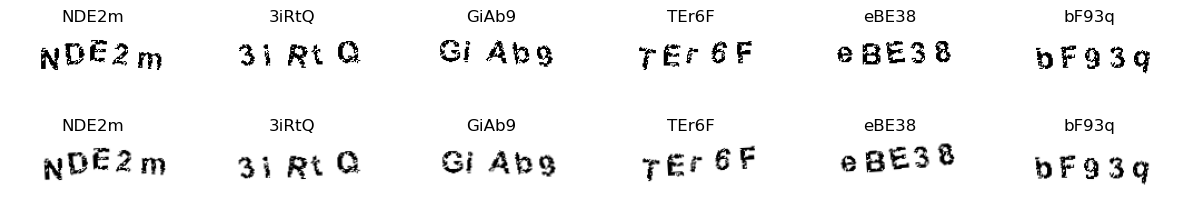

In [6]:
def batches(split, batch_size, shuffle):
    idx, y = data[split]
    order = torch.randperm(len(idx)) if shuffle else torch.arange(len(idx))
    for k in range(0, len(idx), batch_size):
        j = order[k:k + batch_size]
        yield to_input(X[idx[j].to(DEVICE)]), y[j].to(DEVICE)

def augment(x, max_shift=4, max_rot=4):
    """Random shift (px) and rotation (degrees) per image, whole batch at once on the GPU.
    No flips: a mirrored letter is a different letter."""
    b, _, h, w = x.shape
    rnd = lambda: torch.rand(b, device=x.device) * 2 - 1
    ang = rnd() * max_rot * math.pi / 180
    cos, sin = torch.cos(ang), torch.sin(ang)
    tx, ty = rnd() * max_shift * 2 / w, rnd() * max_shift * 2 / h
    theta = torch.stack([torch.stack([cos, -sin * h / w, tx], 1),
                         torch.stack([sin * w / h, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)

x, y = next(batches("train", 6, shuffle=True))
fig, ax = plt.subplots(2, 6, figsize=(15, 2.6))
for k, img in enumerate(torch.cat([x, augment(x)]).cpu()):
    ax[k // 6, k % 6].imshow(img[0], cmap="gray_r", vmin=0, vmax=1)
    ax[k // 6, k % 6].set_title(decode_pred(y[k % 6].tolist()))
    ax[k // 6, k % 6].axis("off")
plt.show()

## 8. Training and evaluation functions

In [7]:
@torch.no_grad()
def predict(model, split, batch_size=1024):
    model.eval()
    return torch.cat([model(x).argmax(-1).cpu() for x, _ in batches(split, batch_size, shuffle=False)])

def evaluate(model, split):
    p, y = predict(model, split), data[split][1]
    return {"exact": (p == y).all(1).float().mean().item(), "char": (p == y).float().mean().item()}

def train(cfg, tag=""):
    """Trains with cfg; keeps the epoch with the best val exact-match. Returns (model, best val)."""
    torch.manual_seed(cfg["seed"])
    model = CaptchaCNN(len(ALPHABET), dropout=cfg["dropout"]).to(DEVICE)
    if cfg["init"]:   # start from a trained model's weights instead of random ones
        model.load_state_dict(torch.load(cfg["init"], map_location=DEVICE)["state_dict"])
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    steps_per_epoch = math.ceil(len(data["train"][0]) / cfg["batch"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=cfg["epochs"] * steps_per_epoch)
    best, best_state, stale = -1.0, None, 0
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        t, total = time.time(), torch.zeros((), device=DEVICE)
        bar = tqdm(batches("train", cfg["batch"], shuffle=True), total=steps_per_epoch,
                   desc=f"{tag}epoch {epoch}/{cfg['epochs']}", leave=False)
        for step, (x, y) in enumerate(bar, 1):
            if cfg["augment"]:
                x = augment(x)
            loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten(), label_smoothing=cfg["smoothing"])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            total += loss.detach()
            if step % 50 == 0:   # reading the loss forces a GPU sync, so only now and then
                bar.set_postfix(loss=f"{total.item() / step:.3f}")
        val = evaluate(model, "val")
        gold_r = evaluate(model, "gold")
        print(f"{tag}epoch {epoch:>2}/{cfg['epochs']}  loss {total.item() / steps_per_epoch:.3f}  "
              f"val exact {val['exact']:.2%}  char {val['char']:.2%}  "
              f"gold exact {gold_r['exact']:.2%}  {time.time() - t:.0f}s", flush=True)
        if val["exact"] > best:
            best, stale = val["exact"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= cfg["patience"]:
                print(f"{tag}stopping early, no val gain for {stale} epochs")
                break
    model.load_state_dict(best_state)
    return model, best

# from scratch, so nothing from v1 carries over. To start from a model instead: init=<path>, epochs=6, lr=5e-4, patience=3
CFG = dict(init=None, epochs=10, batch=256, lr=2e-3, weight_decay=1e-4, dropout=0.3,
           smoothing=0.1, augment=True, patience=4, seed=SEED)

## 9. Train the new model from scratch (~10 min)

In [8]:
model, best_val = train(CFG)
print(f"best val exact: {best_val:.2%}")

epoch 1/10:   0%|          | 0/272 [00:00<?, ?it/s]

epoch 1/10:   0%|          | 1/272 [00:02<09:25,  2.09s/it]

epoch 1/10:   1%|          | 3/272 [00:02<02:54,  1.54it/s]

epoch 1/10:   1%|▏         | 4/272 [00:02<02:17,  1.95it/s]

epoch 1/10:   2%|▏         | 5/272 [00:02<01:54,  2.34it/s]

epoch 1/10:   2%|▏         | 6/272 [00:03<01:38,  2.69it/s]

... (2,721 outputs left out)

epoch 10/10: 100%|█████████▉| 271/272 [01:11<00:00,  3.77it/s, loss=0.738]

epoch 10/10: 100%|██████████| 272/272 [01:11<00:00,  3.75it/s, loss=0.738]

epoch 10/10  loss 0.738  val exact 99.31%  char 99.86%  gold exact 98.50%  74s


best val exact: 99.31%


## 10. Test on gold: the number to beat is 98.5% (round 2 fine-tuned, the teacher here)

val   (  9899 images)  exact 99.31%  char 99.86%


test  ( 19795 images)  exact 99.24%  char 99.85%
gold  (   200 images)  exact 98.50%  char 99.70%
gold, teacher (v2 fine-tuned): 98.50%


gold, v3 baseline: 98.50%
per-position accuracy on gold: ['99.5%', '99.0%', '100.0%', '100.0%', '100.0%']
confusions on gold (true -> predicted): [(('A', '4'), 1), (('a', 'e'), 1), (('g', '9'), 1)]


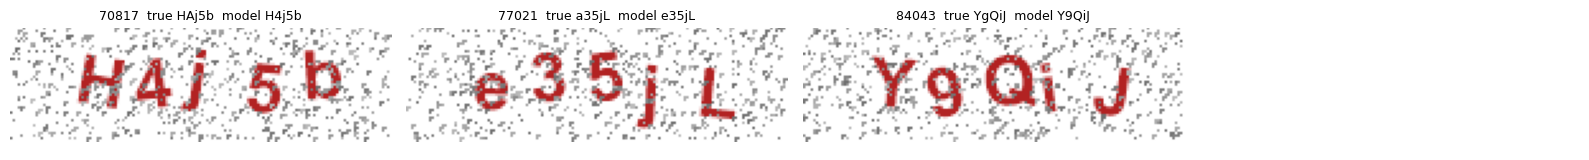

In [9]:
for split in ("val", "test", "gold"):
    r = evaluate(model, split)
    print(f"{split:<5} ({len(data[split][0]):>6} images)  exact {r['exact']:.2%}  char {r['char']:.2%}")

n_checked = sum(bool(g["checked"]) for g in GOLD.values())
if n_checked < len(GOLD):
    print(f"only {n_checked}/{len(GOLD)} gold checked: scores are provisional and flatter the teacher")
teacher, _ = load_model(TEACHER)
for name, m in (("teacher (v2 fine-tuned)", teacher), ("v3 baseline", model)):
    print(f"gold, {name}: {evaluate(m, 'gold')['exact']:.2%}")

p_gold, y_gold = predict(model, "gold"), data["gold"][1]
print("per-position accuracy on gold:", [f"{a:.1%}" for a in (p_gold == y_gold).float().mean(0).tolist()])
mix = Counter((ALPHABET[t], ALPHABET[q]) for pp, yy in zip(p_gold, y_gold)
              for t, q in zip(yy.tolist(), pp.tolist()) if t != q)
print("confusions on gold (true -> predicted):", mix.most_common(10))

gold_rows = split_rows["gold"]
wrong = [k for k in range(len(gold_rows)) if not torch.equal(p_gold[k], y_gold[k])]
cols, rows_n = 4, max(1, math.ceil(len(wrong) / 4))
fig, ax = plt.subplots(rows_n, cols, figsize=(16, 1.6 * rows_n), squeeze=False)
for a in ax.flat:
    a.axis("off")
for a, k in zip(ax.flat, wrong):
    a.imshow(prep.open_captcha(gold_rows[k]["id"]).convert("RGB"))
    a.set_title(f"{gold_rows[k]['id']}  true {gold_rows[k]['label']}  model {decode_pred(p_gold[k].tolist())}", fontsize=9)
plt.tight_layout()
plt.show()

## 11. Save, reload, check the reload predicts the same

In [10]:
torch.save({
    "state_dict": model.state_dict(),
    "alphabet": ALPHABET,
    "length": LENGTH,
    "image_size": (H, W),
    "widths": (32, 64, 128, 192),
    "preprocess": "prep.ink: red mask (r - g > 60 and r - b > 60) -> letters 0, rest 255",
    "config": CFG,
    "trained_on": LABELS_CSV,
    "input": "grayscale HxW, x = 1 - pixel/255 (ink = 1), shape (B, 1, H, W)",
    "scores": {s: evaluate(model, s) for s in ("val", "test", "gold")},
}, MODEL_PATH)

reloaded, ckpt = load_model(MODEL_PATH)
assert torch.equal(predict(reloaded, "gold"), predict(model, "gold")), "reloaded model predicts differently"
print(f"saved {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB), reload OK:", ckpt["scores"])

saved ../models/captcha_cnn_v3.pt (7.3 MB), reload OK: {'val': {'exact': 0.993130624294281, 'char': 0.9986059069633484}, 'test': {'exact': 0.9923717975616455, 'char': 0.9984743595123291}, 'gold': {'exact': 0.9850000143051147, 'char': 0.996999979019165}}


## 12. Review 50 at a time: disagreements with Vision first, then the least confident reads
Enter = right, type the truth if wrong, s = skip, q = quit. Settings (N_REVIEW, FOCUS, POOL) at the top of
`../scripts/review.py`. Reviews go to `../data/reviews.json` (shared with v2). After each batch, re-run 13 and 14.

In [ ]:
%run -i ../scripts/review.py

## 13. Fine-tune the baseline on all reviews → `../models/captcha_cnn_v3_ft.pt` (re-run after each review batch)

In [11]:
%run -i ../scripts/finetune.py

100 reviews, the reviewing model was wrong on 26
each review repeated 20x per epoch


fine-tune epoch 1/2:   0%|          | 0/28 [00:00<?, ?it/s]

fine-tune epoch 1/2:   7%|▋         | 2/28 [00:00<00:03,  7.16it/s]

fine-tune epoch 1/2:  11%|█         | 3/28 [00:00<00:04,  5.24it/s]

fine-tune epoch 1/2:  14%|█▍        | 4/28 [00:00<00:05,  4.57it/s]

fine-tune epoch 1/2:  18%|█▊        | 5/28 [00:01<00:05,  4.26it/s]

... (50 outputs left out)

fine-tune epoch 2/2:  96%|█████████▋| 27/28 [00:06<00:00,  3.74it/s]

fine-tune epoch 2/2: 100%|██████████| 28/28 [00:07<00:00,  3.74it/s]

epoch 2/2  reviewed exact 100.00%  gold exact 98.50%



                  before  ->  after
reviewed  exact  96.00% -> 100.00%   char  99.20% -> 100.00%
gold      exact  98.50% ->  98.50%   char  99.70% ->  99.70%
test      exact  99.24% ->  99.24%   char  99.85% ->  99.85%
saved ../models/captcha_cnn_v3_ft.pt


## 14. What the fine-tune fixed and broke on gold (vs the baseline)

In [12]:
base_model, _ = load_model(MODEL_PATH)
p_base, p_ft, y = predict(base_model, "gold"), predict(ft_model, "gold"), data["gold"][1]
for k, r in enumerate(split_rows["gold"]):
    b, f = torch.equal(p_base[k], y[k]), torch.equal(p_ft[k], y[k])
    if b != f:
        print(f"{'FIXED ' if f else 'BROKEN'} {r['id']}  true {r['label']}  "
              f"baseline {decode_pred(p_base[k].tolist())}  fine-tuned {decode_pred(p_ft[k].tolist())}")